In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [28]:
data = pd.read_csv('/raid/home/md24b010_karthik/iGEM/New_Strategy/Final_raw_Substrate_Sequence.csv')

In [29]:
import pandas as pd

# Copy the original dataframe
final = data.copy()

# Split substrate sequence at cleavage site
final[['left_seq', 'right_seq']] = final['Substrate'].str.split('|', expand=True)

# Get the 4 amino acids immediately to the left of '|'
for i in range(4):
    final[f'pos_{i+1}'] = final['left_seq'].str[-(4-i)]

# Map enzyme/category
final['category'] = final['Enzyme'].map({
    'Serine': 1,
    'Aspartic': 0
})

# One-hot encode the four positions
ohe = pd.get_dummies(
    final[['pos_1', 'pos_2', 'pos_3', 'pos_4']],
    prefix=['pos_1', 'pos_2', 'pos_3', 'pos_4'],
    dtype=int
)

# Combine
final = pd.concat([
    ohe,
    final['category']
], axis=1)

# Optional: reset index
final = final.reset_index(drop=True)


In [30]:
final.describe

<bound method NDFrame.describe of       pos_1_A  pos_1_C  pos_1_D  pos_1_E  pos_1_F  pos_1_G  pos_1_H  pos_1_I  \
0           0        0        0        0        0        0        0        0   
1           0        0        0        0        0        0        0        0   
2           0        0        0        0        0        0        0        0   
3           0        0        0        0        0        1        0        0   
4           0        0        0        0        0        1        0        0   
...       ...      ...      ...      ...      ...      ...      ...      ...   
8294        0        0        0        0        0        0        0        0   
8295        0        0        0        0        0        0        0        0   
8296        0        0        0        0        0        0        0        0   
8297        0        0        0        0        0        0        0        0   
8298        0        0        0        0        0        1        0        0   

     

In [31]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [32]:
# ============================================================
# CELL 1 — LIBRARIES + DATA PREPARATION
# ============================================================

import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Distributions for randomized search
from scipy.stats import loguniform

# XGBoost
from xgboost import XGBClassifier

# Saving models
import joblib


# ============================================================
# SETTINGS
# ============================================================

RANDOM_STATE = 42

# Your machine has 224 logical CPUs.
# 32 workers is a good starting point without oversubscribing
# the machine.
N_JOBS = 32

MODEL_DIR = "saved_models"

os.makedirs(MODEL_DIR, exist_ok=True)

sns.set_style("whitegrid")


# ============================================================
# PREPARE X AND y
# ============================================================

# final should already exist
#
# final:
#   80 OHE feature columns
#   category column

X = final.drop(columns=["category"]).copy()

y = final["category"].astype(int).copy()


# Make sure all features are numeric
X = X.astype(float)


print("Dataset shape:")
print(final.shape)

print("\nX shape:")
print(X.shape)

print("\ny shape:")
print(y.shape)

print("\nClass distribution:")
print(y.value_counts())

print("\nClass proportions:")
print(y.value_counts(normalize=True))


# ============================================================
# 80 : 20 TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    train_size=0.80,
    stratify=y,
    random_state=RANDOM_STATE
)


print("\n" + "=" * 60)
print("TRAIN / TEST SPLIT")
print("=" * 60)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


# ============================================================
# 5-FOLD STRATIFIED CROSS VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)


# ============================================================
# EVALUATION FUNCTION
# ============================================================

def evaluate_model(model, model_name, X_test, y_test):

    # --------------------------------------------------------
    # Predictions
    # --------------------------------------------------------

    y_pred = model.predict(X_test)

    # --------------------------------------------------------
    # Score for ROC curve
    # --------------------------------------------------------

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]

    else:
        y_score = model.decision_function(X_test)

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    auc = roc_auc_score(
        y_test,
        y_score
    )

    # --------------------------------------------------------
    # Print results
    # --------------------------------------------------------

    print("\n")
    print("=" * 70)
    print(model_name)
    print("=" * 70)

    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\nClassification Report:")
    print(
        classification_report(
            y_test,
            y_pred,
            target_names=[
                "Aspartic (0)",
                "Serine (1)"
            ],
            zero_division=0
        )
    )

    # ========================================================
    # CONFUSION MATRIX
    # ========================================================

    cm = confusion_matrix(
        y_test,
        y_pred
    )

    plt.figure(figsize=(6, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[
            "Aspartic (0)",
            "Serine (1)"
        ],
        yticklabels=[
            "Aspartic (0)",
            "Serine (1)"
        ]
    )

    plt.xlabel("Predicted label")
    plt.ylabel("True label")

    plt.title(
        f"{model_name}\nConfusion Matrix"
    )

    plt.tight_layout()
    plt.show()


    # ========================================================
    # ROC CURVE
    # ========================================================

    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_score
    )

    plt.figure(figsize=(7, 6))

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"AUC = {auc:.4f}"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        "k--",
        linewidth=1.5,
        label="Random"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(
        f"{model_name}\nROC Curve"
    )

    plt.legend(
        loc="lower right"
    )

    plt.tight_layout()
    plt.show()


    # --------------------------------------------------------
    # Return results
    # --------------------------------------------------------

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "ROC_AUC": auc
    }


Dataset shape:
(8299, 81)

X shape:
(8299, 80)

y shape:
(8299,)

Class distribution:
category
0    4541
1    3758
Name: count, dtype: int64

Class proportions:
category
0    0.547174
1    0.452826
Name: proportion, dtype: float64

TRAIN / TEST SPLIT
Training samples: 6639
Testing samples : 1660

Training class distribution:
category
0    3633
1    3006
Name: count, dtype: int64

Testing class distribution:
category
0    908
1    752
Name: count, dtype: int64


Training Logistic Regression...
Fitting 5 folds for each of 30 candidates, totalling 150 fits



Best parameters:
{'classifier__C': np.float64(0.2682695795279725), 'classifier__penalty': 'l2', 'classifier__solver': 'lbfgs'}

Best 5-fold CV ROC-AUC: 0.8634

Model saved.


Logistic Regression
Accuracy : 0.7657
Precision: 0.7657
Recall   : 0.6955
F1-score : 0.7289
ROC-AUC  : 0.8465

Classification Report:
              precision    recall  f1-score   support

Aspartic (0)       0.77      0.82      0.79       908
  Serine (1)       0.77      0.70      0.73       752

    accuracy                           0.77      1660
   macro avg       0.77      0.76      0.76      1660
weighted avg       0.77      0.77      0.76      1660



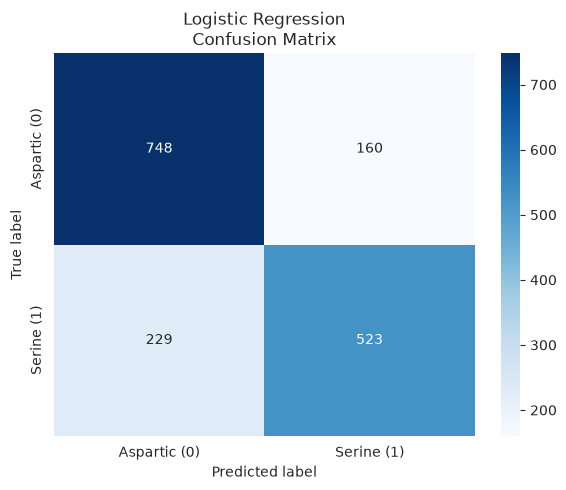

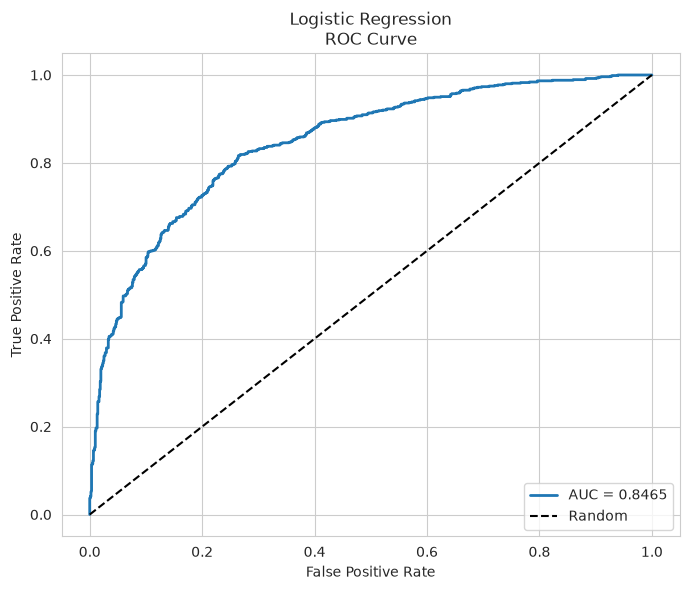

In [33]:
# ============================================================
# CELL 2 — LOGISTIC REGRESSION
# ============================================================

logistic_pipeline = Pipeline([
    
    (
        "scaler",
        StandardScaler()
    ),
    
    (
        "classifier",
        LogisticRegression(
            max_iter=5000,
            random_state=RANDOM_STATE
        )
    )
])


# ------------------------------------------------------------
# Hyperparameters
# ------------------------------------------------------------

logistic_params = {

    "classifier__C": np.logspace(
        -4,
        4,
        15
    ),

    "classifier__penalty": [
        "l2"
    ],

    "classifier__solver": [
        "lbfgs",
        "liblinear"
    ]
}


# ------------------------------------------------------------
# Grid Search
# ------------------------------------------------------------

logistic_search = GridSearchCV(

    estimator=logistic_pipeline,

    param_grid=logistic_params,

    scoring="roc_auc",

    cv=cv,

    n_jobs=N_JOBS,

    verbose=1,

    refit=True
)


print("Training Logistic Regression...")

logistic_search.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# Best parameters
# ------------------------------------------------------------

print("\nBest parameters:")
print(logistic_search.best_params_)

print(
    f"\nBest 5-fold CV ROC-AUC: "
    f"{logistic_search.best_score_:.4f}"
)


# ------------------------------------------------------------
# Save model
# ------------------------------------------------------------

joblib.dump(
    logistic_search.best_estimator_,
    os.path.join(
        MODEL_DIR,
        "logistic_regression.pkl"
    )
)

print("\nModel saved.")


# ------------------------------------------------------------
# Test-set evaluation
# ------------------------------------------------------------

logistic_results = evaluate_model(

    logistic_search.best_estimator_,

    "Logistic Regression",

    X_test,

    y_test
)


Training SVM...
Fitting 5 folds for each of 30 candidates, totalling 150 fits



Best parameters:
{'classifier__C': np.float64(98.77700294007911), 'classifier__gamma': np.float64(0.00018794668241638458)}

Best 5-fold CV ROC-AUC: 0.8610

Model saved.


SVM (RBF)
Accuracy : 0.7355
Precision: 0.7750
Recall   : 0.5864
F1-score : 0.6677
ROC-AUC  : 0.8442

Classification Report:
              precision    recall  f1-score   support

Aspartic (0)       0.71      0.86      0.78       908
  Serine (1)       0.78      0.59      0.67       752

    accuracy                           0.74      1660
   macro avg       0.74      0.72      0.72      1660
weighted avg       0.74      0.74      0.73      1660



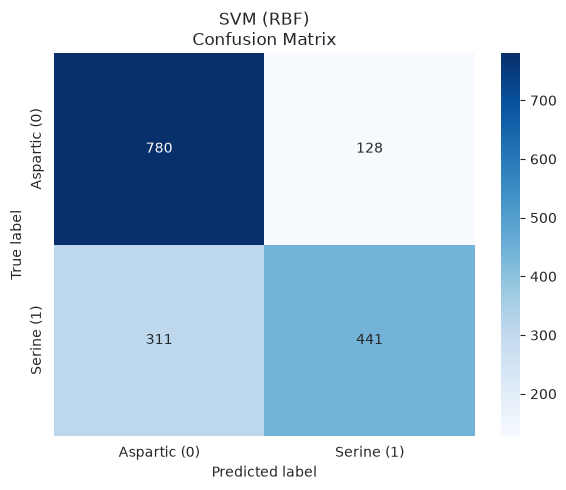

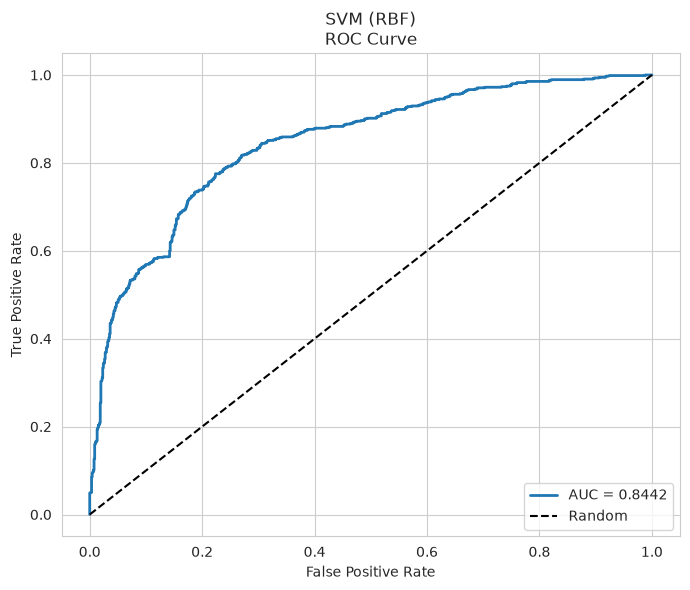

In [34]:
# ============================================================
# CELL 3 — SVM
# ============================================================

svm_pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "classifier",
        SVC(
            kernel="rbf",
            probability=False,
            random_state=RANDOM_STATE
        )
    )
])


# ------------------------------------------------------------
# Hyperparameter distributions
# ------------------------------------------------------------

svm_params = {

    "classifier__C": loguniform(
        1e-3,
        1e3
    ),

    "classifier__gamma": loguniform(
        1e-5,
        1e1
    )
}


# ------------------------------------------------------------
# Randomized Search
# ------------------------------------------------------------

svm_search = RandomizedSearchCV(

    estimator=svm_pipeline,

    param_distributions=svm_params,

    n_iter=30,

    scoring="roc_auc",

    cv=cv,

    n_jobs=N_JOBS,

    random_state=RANDOM_STATE,

    verbose=1,

    refit=True
)


print("Training SVM...")

svm_search.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# Best parameters
# ------------------------------------------------------------

print("\nBest parameters:")
print(svm_search.best_params_)

print(
    f"\nBest 5-fold CV ROC-AUC: "
    f"{svm_search.best_score_:.4f}"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

joblib.dump(
    svm_search.best_estimator_,
    os.path.join(
        MODEL_DIR,
        "svm_rbf.pkl"
    )
)

print("\nModel saved.")


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

svm_results = evaluate_model(

    svm_search.best_estimator_,

    "SVM (RBF)",

    X_test,

    y_test
)


Training Decision Tree...
Fitting 5 folds for each of 50 candidates, totalling 250 fits



Best parameters:
{'min_samples_split': 50, 'min_samples_leaf': 20, 'max_features': None, 'max_depth': None, 'criterion': 'log_loss'}

Best 5-fold CV ROC-AUC: 0.8574

Model saved.


Decision Tree
Accuracy : 0.7723
Precision: 0.7959
Recall   : 0.6689
F1-score : 0.7269
ROC-AUC  : 0.8413

Classification Report:
              precision    recall  f1-score   support

Aspartic (0)       0.76      0.86      0.80       908
  Serine (1)       0.80      0.67      0.73       752

    accuracy                           0.77      1660
   macro avg       0.78      0.76      0.77      1660
weighted avg       0.78      0.77      0.77      1660



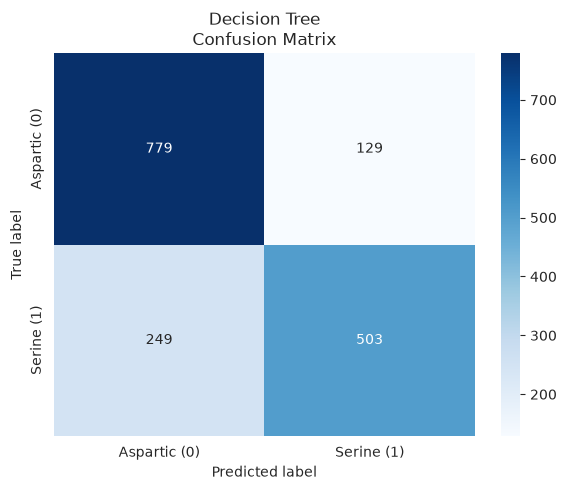

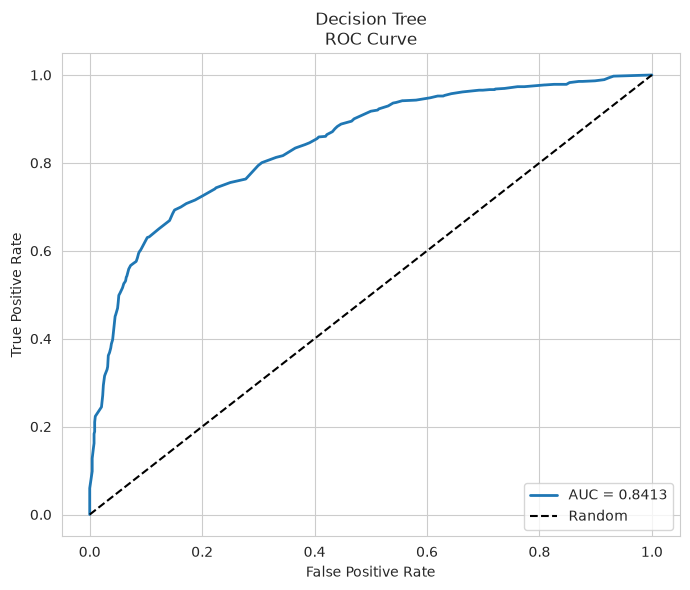

In [35]:
# ============================================================
# CELL 4 — DECISION TREE
# ============================================================

dt = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)


# ------------------------------------------------------------
# Hyperparameters
# ------------------------------------------------------------

dt_params = {

    "max_depth": [
        3,
        5,
        7,
        10,
        15,
        20,
        None
    ],

    "min_samples_split": [
        2,
        5,
        10,
        20,
        50
    ],

    "min_samples_leaf": [
        1,
        2,
        5,
        10,
        20
    ],

    "criterion": [
        "gini",
        "entropy",
        "log_loss"
    ],

    "max_features": [
        None,
        "sqrt",
        "log2"
    ]
}


# ------------------------------------------------------------
# Randomized Search
# ------------------------------------------------------------

dt_search = RandomizedSearchCV(

    estimator=dt,

    param_distributions=dt_params,

    n_iter=50,

    scoring="roc_auc",

    cv=cv,

    n_jobs=N_JOBS,

    random_state=RANDOM_STATE,

    verbose=1,

    refit=True
)


print("Training Decision Tree...")

dt_search.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nBest parameters:")
print(dt_search.best_params_)

print(
    f"\nBest 5-fold CV ROC-AUC: "
    f"{dt_search.best_score_:.4f}"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

joblib.dump(
    dt_search.best_estimator_,
    os.path.join(
        MODEL_DIR,
        "decision_tree.pkl"
    )
)

print("\nModel saved.")


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

dt_results = evaluate_model(

    dt_search.best_estimator_,

    "Decision Tree",

    X_test,

    y_test
)


Training Random Forest...
Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best parameters:
{'n_estimators': 500, 'min_samples_split': 20, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30, 'criterion': 'log_loss', 'class_weight': 'balanced_subsample'}

Best 5-fold CV ROC-AUC: 0.8752

Model saved.


Random Forest
Accuracy : 0.7910
Precision: 0.7922
Recall   : 0.7301
F1-score : 0.7599
ROC-AUC  : 0.8652

Classification Report:
              precision    recall  f1-score   support

Aspartic (0)       0.79      0.84      0.81       908
  Serine (1)       0.79      0.73      0.76       752

    accuracy                           0.79      1660
   macro avg       0.79      0.79      0.79      1660
weighted avg       0.79      0.79      0.79      1660



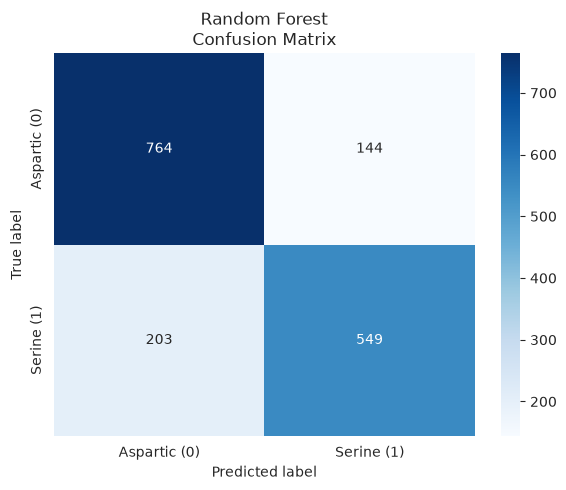

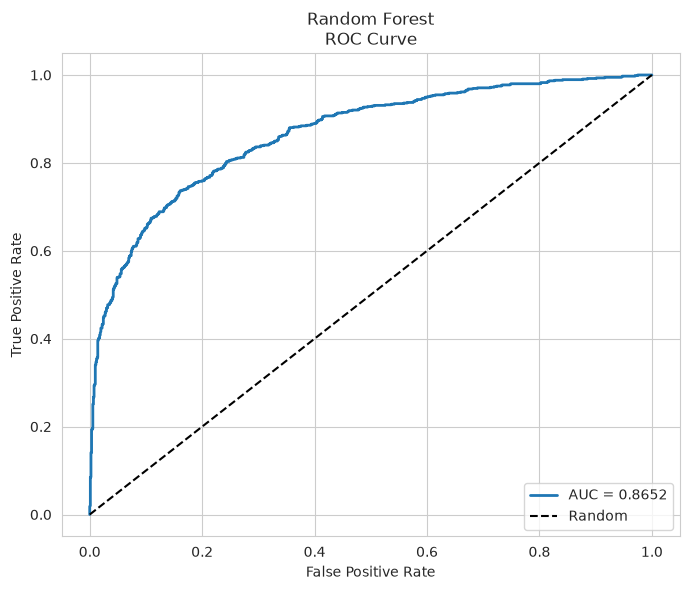

In [36]:
# ============================================================
# CELL 5 — RANDOM FOREST
# ============================================================

rf = RandomForestClassifier(

    random_state=RANDOM_STATE,

    n_jobs=N_JOBS
)


# ------------------------------------------------------------
# Hyperparameters
# ------------------------------------------------------------

rf_params = {

    "n_estimators": [
        300,
        500,
        800,
        1000
    ],

    "max_depth": [
        None,
        5,
        10,
        15,
        20,
        30
    ],

    "min_samples_split": [
        2,
        5,
        10,
        20
    ],

    "min_samples_leaf": [
        1,
        2,
        5,
        10
    ],

    "max_features": [
        "sqrt",
        "log2",
        None
    ],

    "criterion": [
        "gini",
        "entropy",
        "log_loss"
    ],

    "class_weight": [
        None,
        "balanced",
        "balanced_subsample"
    ]
}


# ------------------------------------------------------------
# Randomized Search
# ------------------------------------------------------------

rf_search = RandomizedSearchCV(

    estimator=rf,

    param_distributions=rf_params,

    n_iter=50,

    scoring="roc_auc",

    cv=cv,

    n_jobs=N_JOBS,

    random_state=RANDOM_STATE,

    verbose=1,

    refit=True
)


print("Training Random Forest...")

rf_search.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nBest parameters:")
print(rf_search.best_params_)

print(
    f"\nBest 5-fold CV ROC-AUC: "
    f"{rf_search.best_score_:.4f}"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

joblib.dump(
    rf_search.best_estimator_,
    os.path.join(
        MODEL_DIR,
        "random_forest.pkl"
    )
)

print("\nModel saved.")


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

rf_results = evaluate_model(

    rf_search.best_estimator_,

    "Random Forest",

    X_test,

    y_test
)


Training KNN...
Fitting 5 folds for each of 108 candidates, totalling 540 fits



Best parameters:
{'classifier__metric': 'manhattan', 'classifier__n_neighbors': 11, 'classifier__p': 1, 'classifier__weights': 'uniform'}

Best 5-fold CV ROC-AUC: 0.8377

Model saved.


KNN
Accuracy : 0.7566
Precision: 0.7219
Recall   : 0.7527
F1-score : 0.7370
ROC-AUC  : 0.8315

Classification Report:
              precision    recall  f1-score   support

Aspartic (0)       0.79      0.76      0.77       908
  Serine (1)       0.72      0.75      0.74       752

    accuracy                           0.76      1660
   macro avg       0.75      0.76      0.76      1660
weighted avg       0.76      0.76      0.76      1660



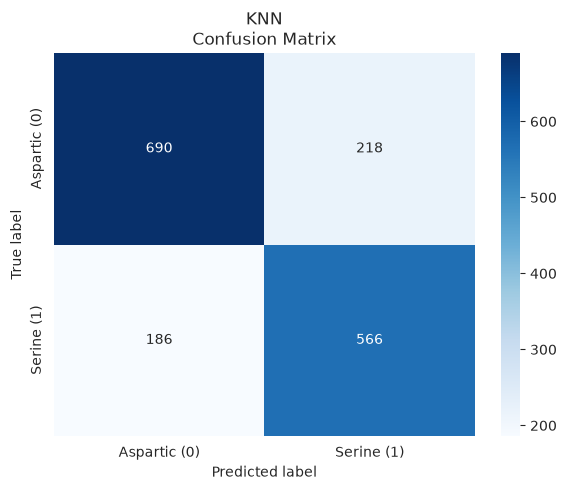

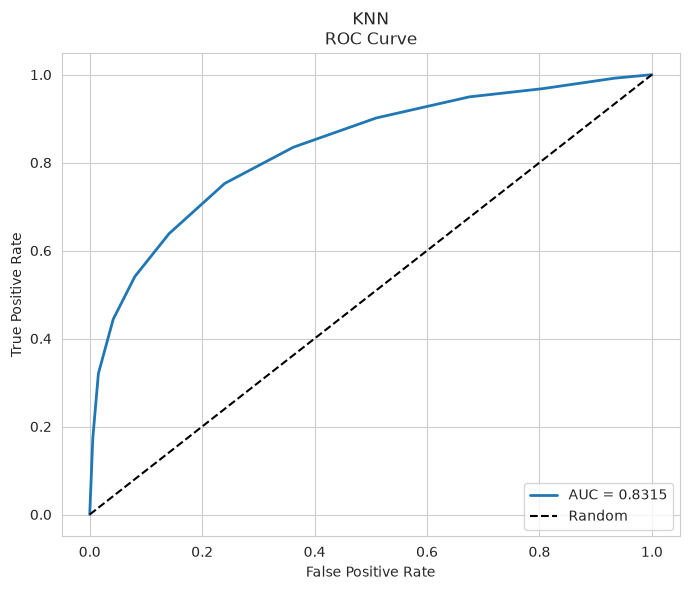

In [37]:
# ============================================================
# CELL 6 — KNN
# ============================================================

knn_pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "classifier",
        KNeighborsClassifier()
    )
])


# ------------------------------------------------------------
# Hyperparameters
# ------------------------------------------------------------

knn_params = {

    "classifier__n_neighbors": [
        3,
        5,
        7,
        9,
        11,
        15,
        21,
        31,
        51
    ],

    "classifier__weights": [
        "uniform",
        "distance"
    ],

    "classifier__metric": [
        "euclidean",
        "manhattan",
        "minkowski"
    ],

    "classifier__p": [
        1,
        2
    ]
}


# ------------------------------------------------------------
# Grid Search
# ------------------------------------------------------------

knn_search = GridSearchCV(

    estimator=knn_pipeline,

    param_grid=knn_params,

    scoring="roc_auc",

    cv=cv,

    n_jobs=N_JOBS,

    verbose=1,

    refit=True
)


print("Training KNN...")

knn_search.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nBest parameters:")
print(knn_search.best_params_)

print(
    f"\nBest 5-fold CV ROC-AUC: "
    f"{knn_search.best_score_:.4f}"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

joblib.dump(
    knn_search.best_estimator_,
    os.path.join(
        MODEL_DIR,
        "knn.pkl"
    )
)

print("\nModel saved.")


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

knn_results = evaluate_model(

    knn_search.best_estimator_,

    "KNN",

    X_test,

    y_test
)


Training XGBoost...
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Best parameters:
{'subsample': 0.9, 'reg_lambda': 2, 'reg_alpha': 0.1, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.1, 'gamma': 0.1, 'colsample_bytree': 0.6}

Best 5-fold CV ROC-AUC: 0.8762

Model saved.


XGBoost
Accuracy : 0.7928
Precision: 0.7931
Recall   : 0.7340
F1-score : 0.7624
ROC-AUC  : 0.8622

Classification Report:
              precision    recall  f1-score   support

Aspartic (0)       0.79      0.84      0.82       908
  Serine (1)       0.79      0.73      0.76       752

    accuracy                           0.79      1660
   macro avg       0.79      0.79      0.79      1660
weighted avg       0.79      0.79      0.79      1660



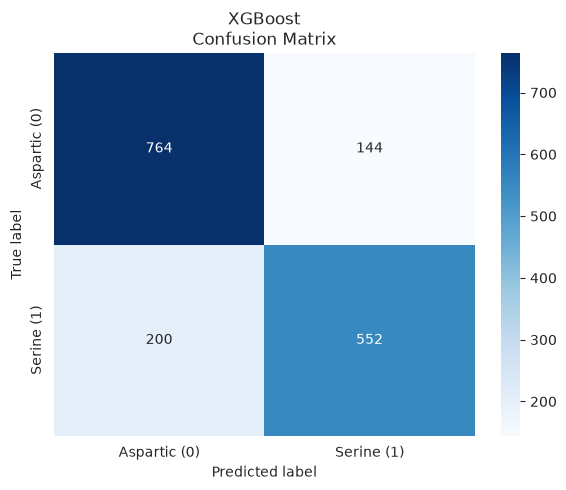

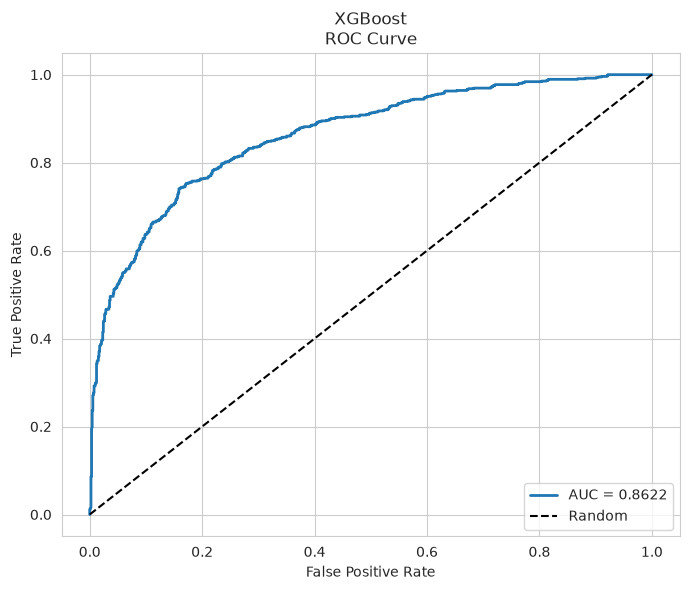

In [38]:
# ============================================================
# CELL 7 — XGBOOST
# ============================================================

xgb = XGBClassifier(

    objective="binary:logistic",

    eval_metric="logloss",

    tree_method="hist",

    random_state=RANDOM_STATE,

    n_jobs=N_JOBS,

    verbosity=0
)


# ------------------------------------------------------------
# Hyperparameters
# ------------------------------------------------------------

xgb_params = {

    "n_estimators": [
        200,
        300,
        500,
        800
    ],

    "max_depth": [
        2,
        3,
        4,
        5,
        6,
        8
    ],

    "learning_rate": [
        0.01,
        0.03,
        0.05,
        0.1,
        0.2
    ],

    "subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],

    "colsample_bytree": [
        0.6,
        0.8,
        1.0
    ],

    "min_child_weight": [
        1,
        3,
        5,
        10
    ],

    "gamma": [
        0,
        0.1,
        0.3,
        0.5
    ],

    "reg_alpha": [
        0,
        0.01,
        0.1,
        1
    ],

    "reg_lambda": [
        1,
        2,
        5,
        10
    ]
}


# ------------------------------------------------------------
# Randomized Search
# ------------------------------------------------------------

xgb_search = RandomizedSearchCV(

    estimator=xgb,

    param_distributions=xgb_params,

    n_iter=60,

    scoring="roc_auc",

    cv=cv,

    n_jobs=N_JOBS,

    random_state=RANDOM_STATE,

    verbose=1,

    refit=True
)


print("Training XGBoost...")

xgb_search.fit(
    X_train,
    y_train
)


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nBest parameters:")
print(xgb_search.best_params_)

print(
    f"\nBest 5-fold CV ROC-AUC: "
    f"{xgb_search.best_score_:.4f}"
)


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

joblib.dump(
    xgb_search.best_estimator_,
    os.path.join(
        MODEL_DIR,
        "xgboost.pkl"
    )
)

print("\nModel saved.")


# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

xgb_results = evaluate_model(

    xgb_search.best_estimator_,

    "XGBoost",

    X_test,

    y_test
)


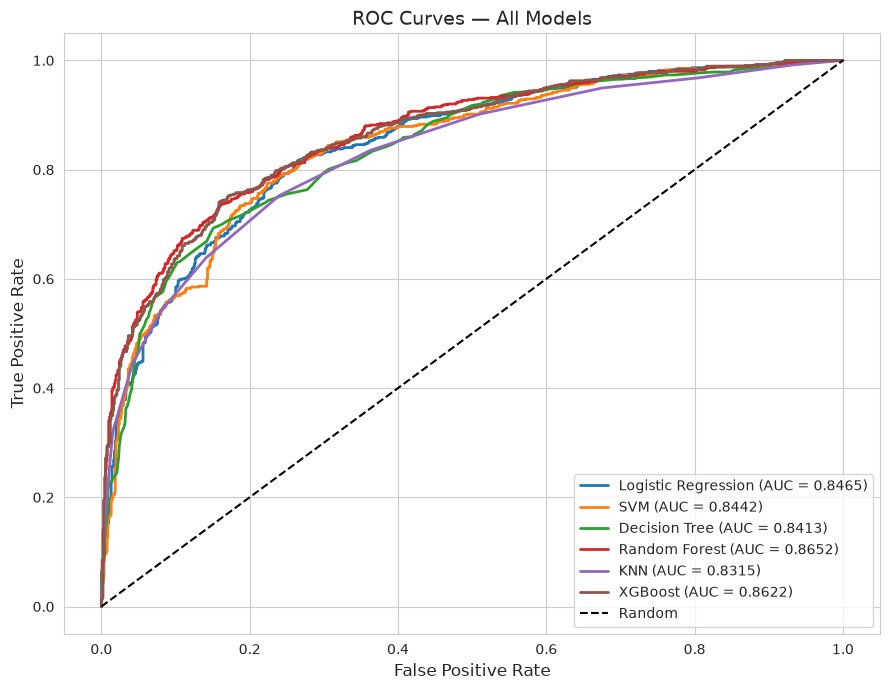

In [39]:
# ============================================================
# CELL 9 — COMBINED ROC CURVES
# ============================================================

models = {

    "Logistic Regression":
        logistic_search.best_estimator_,

    "SVM":
        svm_search.best_estimator_,

    "Decision Tree":
        dt_search.best_estimator_,

    "Random Forest":
        rf_search.best_estimator_,

    "KNN":
        knn_search.best_estimator_,

    "XGBoost":
        xgb_search.best_estimator_
}


plt.figure(
    figsize=(9, 7)
)


for name, model in models.items():

    # Get prediction score

    if hasattr(
        model,
        "predict_proba"
    ):

        y_score = model.predict_proba(
            X_test
        )[:, 1]

    else:

        y_score = model.decision_function(
            X_test
        )


    # ROC

    fpr, tpr, _ = roc_curve(
        y_test,
        y_score
    )


    # AUC

    auc = roc_auc_score(
        y_test,
        y_score
    )


    # Plot

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc:.4f})"
    )


# Random classifier

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5,
    label="Random"
)


plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "ROC Curves — All Models",
    fontsize=14
)

plt.legend(
    loc="lower right"
)

plt.tight_layout()

plt.show()


In [40]:
# ============================================================
# CELL 10 — SAVED MODELS
# ============================================================

print("Models saved in:", MODEL_DIR)
print()

for filename in sorted(
    os.listdir(MODEL_DIR)
):

    if filename.endswith(".pkl"):

        path = os.path.join(
            MODEL_DIR,
            filename
        )

        size_mb = (
            os.path.getsize(path)
            / (1024 ** 2)
        )

        print(
            f"{filename:30s} "
            f"{size_mb:.2f} MB"
        )


Models saved in: saved_models

decision_tree.pkl              0.02 MB
knn.pkl                        4.11 MB
logistic_regression.pkl        0.00 MB
random_forest.pkl              39.92 MB
svm_rbf.pkl                    2.14 MB
xgboost.pkl                    0.51 MB


In [41]:
# ============================================================
# CELL 1
# Generate all 20^4 = 160,000 possible sequences
# ============================================================

import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr

import joblib
import os


# ============================================================
# 20 AMINO ACIDS
# ============================================================
#
# IMPORTANT:
# We need exactly 20 residues for 20^4.
#
# Here I use the standard 20 amino acids.
# 'n' (norleucine) is NOT included in this exhaustive
# 20^4 space.
#
# If your OHE model was trained using 'n' instead of one
# standard amino acid, change this list accordingly.
# ============================================================

AA20 = [
    'A', 'C', 'D', 'E', 'F',
    'G', 'H', 'I', 'K', 'L',
    'M', 'N', 'P', 'Q', 'R',
    'S', 'T', 'V', 'W', 'Y'
]

print("Number of amino acids:", len(AA20))


# ============================================================
# GENERATE ALL 20^4 SEQUENCES
# ============================================================

all_sequences = [
    ''.join(x)
    for x in itertools.product(AA20, repeat=4)
]

print("Number of sequences:", len(all_sequences))

assert len(all_sequences) == 20**4


# ============================================================
# DATAFRAME
# ============================================================

all_seq_df = pd.DataFrame(
    [list(seq) for seq in all_sequences],
    columns=[
        "P1",
        "P2",
        "P3",
        "P4"
    ]
)

all_seq_df["Sequence"] = all_seq_df[
    ["P1", "P2", "P3", "P4"]
].agg(''.join, axis=1)


print("\nGenerated dataframe:")
display(all_seq_df.head())

print("\nShape:")
print(all_seq_df.shape)


# ============================================================
# YOUR EXPERIMENTAL ORDERS
# ============================================================

p1_order = [
    'Q', 'L', 'M', 'I', 'E',
    'N', 'n', 'K', 'R', 'G',
    'T', 'S', 'Y', 'W', 'F',
    'V', 'H', 'D', 'P'
]

p2_order = [
    'H', 'L', 'M', 'n', 'P',
    'A', 'G', 'S', 'T', 'I',
    'E', 'R', 'K', 'D', 'N',
    'Q', 'Y', 'F', 'V', 'W'
]

p3_order = [
    'n', 'Y', 'F', 'W', 'L',
    'I', 'M', 'A', 'V', 'H',
    'E', 'Q', 'R', 'T', 'S',
    'G', 'N', 'K', 'D', 'P'
]

p4_order = [
    'n', 'M', 'L', 'I', 'W',
    'V', 'P', 'A', 'T', 'Y',
    'F', 'G', 'Q', 'S', 'R',
    'H', 'E', 'K', 'D', 'N'
]


# ============================================================
# CHECK WHICH AMINO ACIDS ARE MISSING / EXTRA
# ============================================================

orders = {
    "P1": p1_order,
    "P2": p2_order,
    "P3": p3_order,
    "P4": p4_order
}

print("\nAmino-acid differences between experimental orders "
      "and standard 20-AA set:")

for position, order in orders.items():

    order_set = set(order)
    
    missing_from_order = sorted(
        set(AA20) - order_set
    )
    
    extra_in_order = sorted(
        order_set - set(AA20)
    )
    
    print(f"\n{position}")
    print("Missing from experimental order:", missing_from_order)
    print("Extra in experimental order:", extra_in_order)


# ============================================================
# FUNCTION TO CREATE MODEL FEATURES
# ============================================================
#
# This assumes your `final` dataframe was created using
# one-hot encoded columns named something like:
#
# P1_A, P1_C, ...
# P2_A, P2_C, ...
#
# If your actual column names are different, inspect:
#
# print(X.columns.tolist())
#
# and modify feature construction below.
# ============================================================

feature_columns = X.columns.tolist()

print("\nNumber of model features:")
print(len(feature_columns))


def sequences_to_model_features(seq_df, feature_columns):

    """
    Convert P1-P4 amino-acid sequences into the exact
    one-hot feature representation expected by the model.
    """

    n = len(seq_df)

    X_new = pd.DataFrame(
        0,
        index=np.arange(n),
        columns=feature_columns,
        dtype=np.float32
    )

    positions = ["P1", "P2", "P3", "P4"]

    for pos in positions:

        for aa in AA20:

            possible_names = [
                f"{pos}_{aa}",
                f"{pos}{aa}",
                f"{pos}-{aa}"
            ]

            matching = [
                c for c in possible_names
                if c in X_new.columns
            ]

            if len(matching) > 0:

                X_new.loc[
                    seq_df[pos].values == aa,
                    matching[0]
                ] = 1.0

    return X_new


Number of amino acids: 20
Number of sequences: 160000

Generated dataframe:


,P1,P2,P3,P4,Sequence
0,A,A,A,A,AAAA
1,A,A,A,C,AAAC
2,A,A,A,D,AAAD
3,A,A,A,E,AAAE
4,A,A,A,F,AAAF



Shape:
(160000, 5)

Amino-acid differences between experimental orders and standard 20-AA set:

P1
Missing from experimental order: ['A', 'C']
Extra in experimental order: ['n']

P2
Missing from experimental order: ['C']
Extra in experimental order: ['n']

P3
Missing from experimental order: ['C']
Extra in experimental order: ['n']

P4
Missing from experimental order: ['C']
Extra in experimental order: ['n']

Number of model features:
80


In [42]:
print(X.columns.tolist())


['pos_1_A', 'pos_1_C', 'pos_1_D', 'pos_1_E', 'pos_1_F', 'pos_1_G', 'pos_1_H', 'pos_1_I', 'pos_1_K', 'pos_1_L', 'pos_1_M', 'pos_1_N', 'pos_1_P', 'pos_1_Q', 'pos_1_R', 'pos_1_S', 'pos_1_T', 'pos_1_V', 'pos_1_W', 'pos_1_Y', 'pos_2_A', 'pos_2_C', 'pos_2_D', 'pos_2_E', 'pos_2_F', 'pos_2_G', 'pos_2_H', 'pos_2_I', 'pos_2_K', 'pos_2_L', 'pos_2_M', 'pos_2_N', 'pos_2_P', 'pos_2_Q', 'pos_2_R', 'pos_2_S', 'pos_2_T', 'pos_2_V', 'pos_2_W', 'pos_2_Y', 'pos_3_A', 'pos_3_C', 'pos_3_D', 'pos_3_E', 'pos_3_F', 'pos_3_G', 'pos_3_H', 'pos_3_I', 'pos_3_K', 'pos_3_L', 'pos_3_M', 'pos_3_N', 'pos_3_P', 'pos_3_Q', 'pos_3_R', 'pos_3_S', 'pos_3_T', 'pos_3_V', 'pos_3_W', 'pos_3_Y', 'pos_4_A', 'pos_4_C', 'pos_4_D', 'pos_4_E', 'pos_4_F', 'pos_4_G', 'pos_4_H', 'pos_4_I', 'pos_4_K', 'pos_4_L', 'pos_4_M', 'pos_4_N', 'pos_4_P', 'pos_4_Q', 'pos_4_R', 'pos_4_S', 'pos_4_T', 'pos_4_V', 'pos_4_W', 'pos_4_Y']


In [43]:
def sequences_to_model_features(seq_df, feature_columns):

    X_new = pd.DataFrame(
        0,
        index=seq_df.index,
        columns=feature_columns,
        dtype=np.float32
    )

    for i, pos in enumerate(["P1", "P2", "P3", "P4"], start=1):

        for aa in AA20:

            col = f"pos_{i}_{aa}"

            if col in X_new.columns:

                X_new.loc[
                    seq_df[pos] == aa,
                    col
                ] = 1.0

    return X_new


In [44]:
# ============================================================
# CELL 2
# Generate predictions for all 160,000 sequences
# ============================================================

# ------------------------------------------------------------
# Convert sequences to model features
# ------------------------------------------------------------

X_all = sequences_to_model_features(
    all_seq_df,
    feature_columns
)

print("Model input shape:")
print(X_all.shape)


# ------------------------------------------------------------
# Load models
# ------------------------------------------------------------

models = {

    "Logistic Regression":
        logistic_search.best_estimator_,

    "SVM":
        svm_search.best_estimator_,

    "Decision Tree":
        dt_search.best_estimator_,

    "Random Forest":
        rf_search.best_estimator_,

    "KNN":
        knn_search.best_estimator_,

    "XGBoost":
        xgb_search.best_estimator_
}


# ============================================================
# PREDICTION FUNCTION
# ============================================================

def get_model_probability(model, X):

    """
    Return a score representing probability of class 1
    (Serine / cleavage).

    For models with predict_proba:
        returns P(class=1)

    For SVM trained with probability=False:
        returns decision score.
    """

    if hasattr(model, "predict_proba"):

        return model.predict_proba(X)[:, 1]

    else:

        return model.decision_function(X)


# ============================================================
# PREDICT ALL 160,000 SEQUENCES
# ============================================================

prediction_df = all_seq_df.copy()


for model_name, model in models.items():

    print(
        f"Predicting with {model_name}..."
    )

    prediction_df[model_name] = (
        get_model_probability(
            model,
            X_all
        )
    )


print("\nPrediction dataframe:")
display(prediction_df.head())

print("\nShape:")
print(prediction_df.shape)


Model input shape:
(160000, 80)
Predicting with Logistic Regression...
Predicting with SVM...
Predicting with Decision Tree...
Predicting with Random Forest...
Predicting with KNN...
Predicting with XGBoost...

Prediction dataframe:


,P1,P2,P3,P4,Sequence,Logistic Regression,SVM,Decision Tree,Random Forest,KNN,XGBoost
0,A,A,A,A,AAAA,0.713333,-0.435731,0.819277,0.804331,0.909091,0.880592
1,A,A,A,C,AAAC,0.536895,-0.786896,0.364486,0.531639,0.727273,0.587354
2,A,A,A,D,AAAD,0.941579,1.203639,0.937500,0.929368,1.000000,0.961140
3,A,A,A,E,AAAE,0.629937,-0.716113,0.500000,0.546539,0.727273,0.551847
4,A,A,A,F,AAAF,0.104097,-0.962035,0.071429,0.192673,0.636364,0.094592



Shape:
(160000, 11)


In [46]:
# ============================================================
# CELL 3
# Calculate positional preference
# ============================================================

model_names = list(models.keys())

positions = [
    "P1",
    "P2",
    "P3",
    "P4"
]


def calculate_positional_preference(
    prediction_df,
    model_name
):

    records = []

    for position in positions:

        for aa in AA20:

            subset = prediction_df[
                prediction_df[position] == aa
            ]

            probability = subset[
                model_name
            ].mean()

            records.append({

                "Position": position,

                "AA": aa,

                "Probability": probability,

                "N_sequences": len(subset)

            })

    return pd.DataFrame(records)


# ------------------------------------------------------------
# Calculate for every model
# ------------------------------------------------------------

preference = {}

for model_name in model_names:

    preference[model_name] = (
        calculate_positional_preference(
            prediction_df,
            model_name
        )
    )


# ------------------------------------------------------------
# Check
# ------------------------------------------------------------

display(
    preference["Logistic Regression"].head(20)
)


,Position,AA,Probability,N_sequences
0,P1,A,0.336149,8000
1,P1,C,0.270039,8000
2,P1,D,0.191696,8000
3,P1,E,0.217433,8000
4,P1,F,0.305344,8000
5,P1,G,0.316917,8000
6,P1,H,0.323584,8000
7,P1,I,0.435736,8000
8,P1,K,0.500657,8000
9,P1,L,0.323049,8000


In [47]:
# ============================================================
# CELL 4
# Prepare experimental ranks
# ============================================================

experimental_orders = {
    "P1": p1_order,
    "P2": p2_order,
    "P3": p3_order,
    "P4": p4_order
}


def get_common_rank_table(
    preference_df,
    experimental_order
):

    # Rank from experimental order
    experimental_rank = {
        aa: rank + 1
        for rank, aa in enumerate(
            experimental_order
        )
    }

    result = preference_df.copy()

    result["Experimental_Rank"] = (
        result["AA"].map(
            experimental_rank
        )
    )

    # Only compare amino acids present in
    # both datasets
    result = result.dropna(
        subset=["Experimental_Rank"]
    )

    # Model preference rank:
    # rank 1 = highest predicted preference
    result["Model_Rank"] = (
        result["Probability"]
        .rank(
            ascending=False,
            method="average"
        )
    )

    return result


# ------------------------------------------------------------
# Apply to every model and position
# ------------------------------------------------------------

rank_tables = {}

for model_name in model_names:

    rank_tables[model_name] = {}

    for position in positions:

        pref = preference[
            model_name
        ]

        pref_position = pref[
            pref["Position"] == position
        ].copy()

        rank_tables[
            model_name
        ][position] = get_common_rank_table(
            pref_position,
            experimental_orders[position]
        )


# Example
display(
    rank_tables[
        "Logistic Regression"
    ]["P1"]
)


,Position,AA,Probability,N_sequences,Experimental_Rank,Model_Rank
2,P1,D,0.191696,8000,18.0,18.0
3,P1,E,0.217433,8000,5.0,17.0
4,P1,F,0.305344,8000,15.0,13.0
5,P1,G,0.316917,8000,10.0,11.0
6,P1,H,0.323584,8000,17.0,9.0
7,P1,I,0.435736,8000,4.0,3.0
8,P1,K,0.500657,8000,8.0,1.0
9,P1,L,0.323049,8000,2.0,10.0
10,P1,M,0.371278,8000,3.0,7.0
11,P1,N,0.230829,8000,6.0,16.0


In [48]:
# ============================================================
# CELL 5
# SPEARMAN CORRELATION
# ============================================================

spearman_results = []


for model_name in model_names:

    for position in positions:

        df_rank = rank_tables[
            model_name
        ][position]

        rho, pvalue = spearmanr(

            df_rank["Experimental_Rank"],

            df_rank["Model_Rank"]

        )

        spearman_results.append({

            "Model": model_name,

            "Position": position,

            "Spearman_rho": rho,

            "p_value": pvalue,

            "N_AA_compared": len(df_rank)

        })


spearman_df = pd.DataFrame(
    spearman_results
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print(
    "Spearman correlation between "
    "experimental order and model preference:"
)

display(
    spearman_df.round(4)
)


Spearman correlation between experimental order and model preference:


,Model,Position,Spearman_rho,p_value,N_AA_compared
0,Logistic Regression,P1,0.2136,0.3947,18
1,Logistic Regression,P2,0.0965,0.6943,19
2,Logistic Regression,P3,-0.0474,0.8473,19
3,Logistic Regression,P4,-0.3789,0.1096,19
4,SVM,P1,0.0155,0.9514,18
5,SVM,P2,0.0772,0.7534,19
6,SVM,P3,-0.0281,0.9092,19
7,SVM,P4,-0.3947,0.0944,19
8,Decision Tree,P1,0.2933,0.2376,18
9,Decision Tree,P2,-0.0684,0.7809,19


In [49]:
# ============================================================
# CELL 6
# 2 x 2 POSITIONAL PREFERENCE GRAPH
# ============================================================

def plot_model_preference(
    model_name,
    preference_dict,
    experimental_orders
):

    fig, axes = plt.subplots(
        2,
        2,
        figsize=(18, 12)
    )

    axes = axes.flatten()


    for idx, position in enumerate(positions):

        ax = axes[idx]

        # ----------------------------------------------------
        # Preference data
        # ----------------------------------------------------

        df = preference_dict[
            model_name
        ]

        df = df[
            df["Position"] == position
        ].copy()


        # ----------------------------------------------------
        # Use experimental order for x-axis
        # ----------------------------------------------------

        order = experimental_orders[
            position
        ]

        # Only use amino acids that are
        # present in the generated 20-AA space
        plot_order = [
            aa for aa in order
            if aa in AA20
        ]


        df = df.set_index("AA")

        df = df.loc[
            plot_order
        ].reset_index()


        # ----------------------------------------------------
        # Plot
        # ----------------------------------------------------

        bars = ax.bar(
            df["AA"],
            df["Probability"],
            color="steelblue",
            edgecolor="black",
            linewidth=0.5
        )


        # ----------------------------------------------------
        # Spearman
        # ----------------------------------------------------

        rank_df = rank_tables[
            model_name
        ][position]

        rho, pvalue = spearmanr(

            rank_df["Experimental_Rank"],

            rank_df["Model_Rank"]

        )


        # ----------------------------------------------------
        # Formatting
        # ----------------------------------------------------

        ax.set_title(
            f"{position}   Spearman ρ = {rho:.3f}",
            fontsize=14,
            fontweight="bold"
        )

        ax.set_xlabel(
            "Amino acid",
            fontsize=11
        )

        ax.set_ylabel(
            "Predicted cleavage probability",
            fontsize=11
        )

        ax.tick_params(
            axis="x",
            rotation=45
        )

        ax.set_ylim(
            0,
            max(df["Probability"]) * 1.15
        )


        # Add values above bars

        for bar, value in zip(
            bars,
            df["Probability"]
        ):

            ax.text(
                bar.get_x() +
                bar.get_width() / 2,

                bar.get_height(),

                f"{value:.3f}",

                ha="center",
                va="bottom",

                fontsize=8
            )


    fig.suptitle(
        f"{model_name}\n"
        f"Positional Amino-Acid Preference",
        fontsize=18,
        fontweight="bold"
    )


    plt.tight_layout(
        rect=[
            0,
            0,
            1,
            0.94
        ]
    )

    plt.show()


Logistic Regression


,Model,Position,Spearman_rho,p_value,N_AA_compared
0,Logistic Regression,P1,0.2136,0.3947,18
1,Logistic Regression,P2,0.0965,0.6943,19
2,Logistic Regression,P3,-0.0474,0.8473,19
3,Logistic Regression,P4,-0.3789,0.1096,19



Positional preference:


Position,P1,P2,P3,P4
AA,,,,
A,0.3361,0.4626,0.3985,0.4275
C,0.2700,0.4421,0.2218,0.2826
D,0.1917,0.3866,0.2086,0.7826
E,0.2174,0.4677,0.2812,0.3523
F,0.3053,0.2529,0.2908,0.0489
G,0.3169,0.4017,0.4482,0.2703
H,0.3236,0.2875,0.4188,0.1650
I,0.4357,0.2233,0.1632,0.2049
K,0.5007,0.3513,0.3575,0.3220


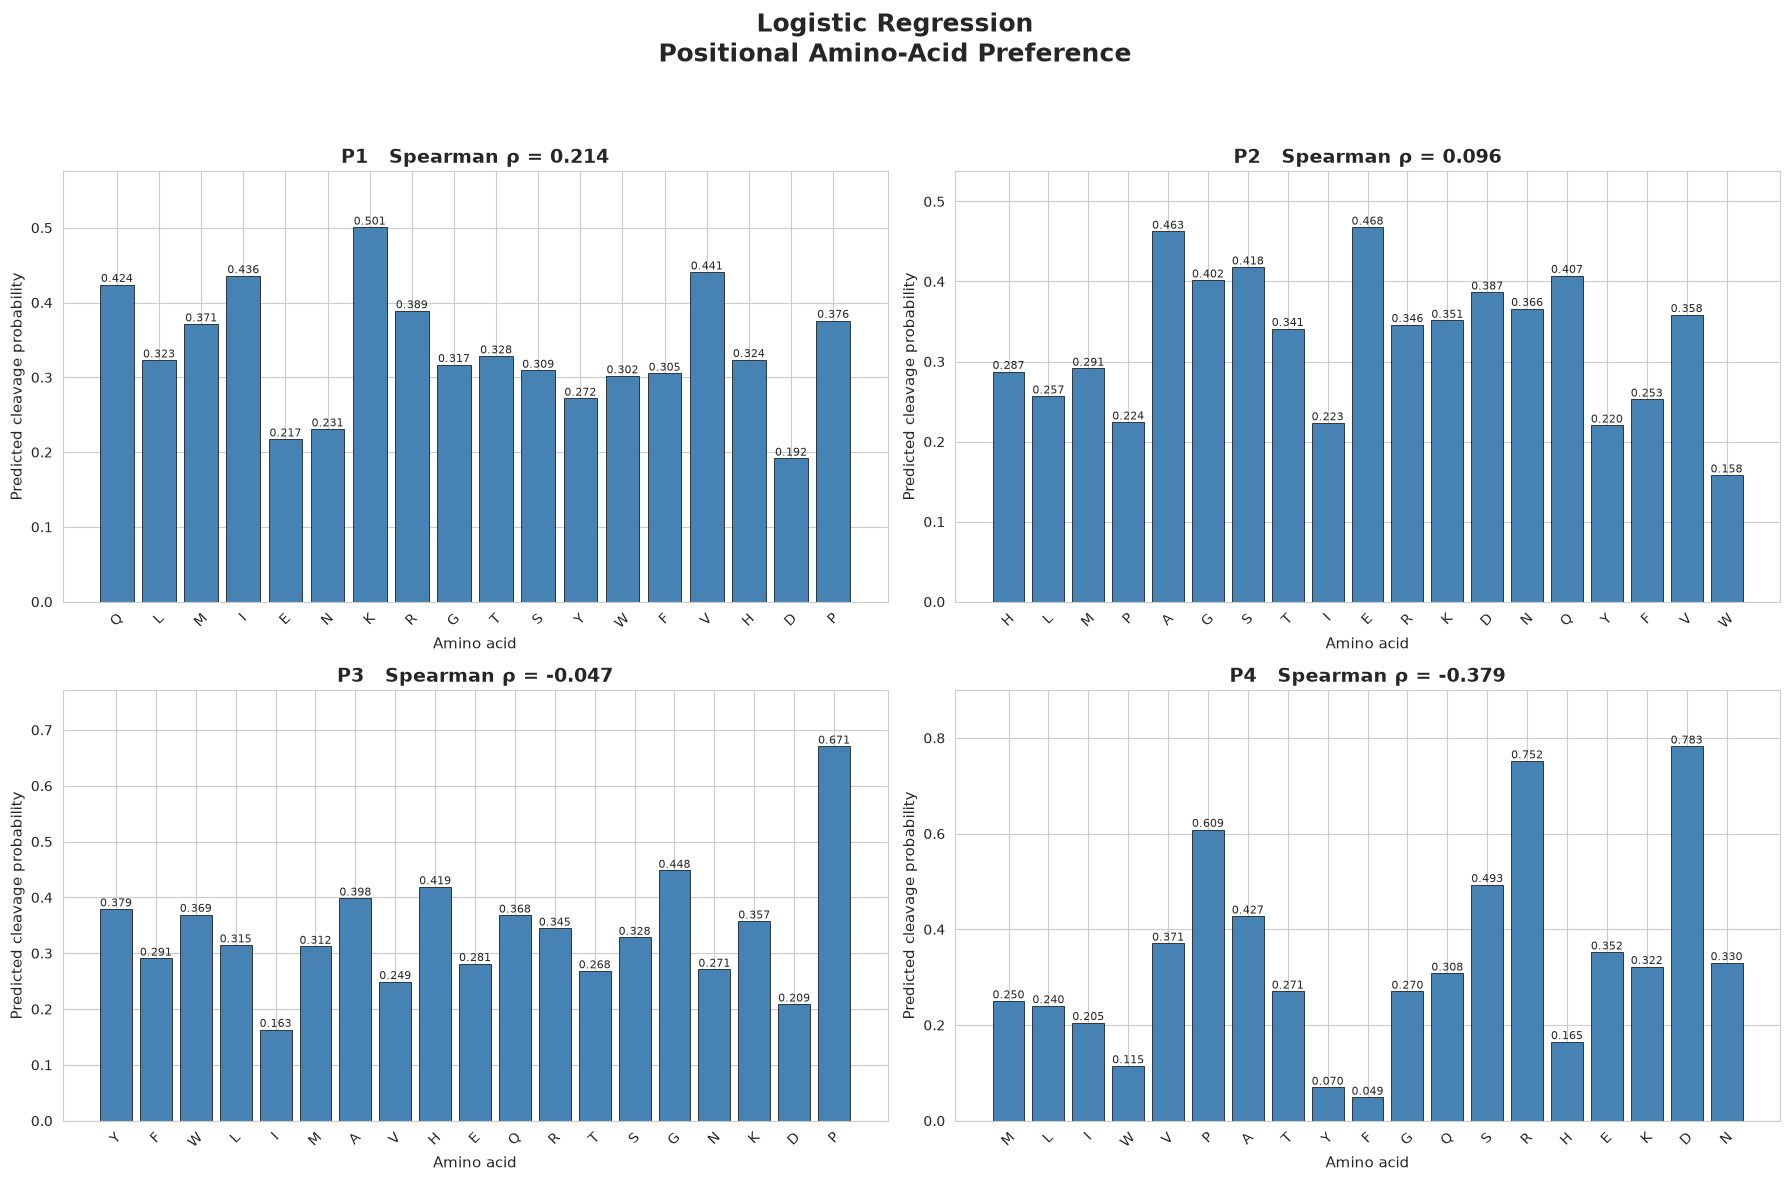

In [50]:
# ============================================================
# CELL 7 — LOGISTIC REGRESSION
# ============================================================

model_name = "Logistic Regression"


print("=" * 70)
print(model_name)
print("=" * 70)


# ------------------------------------------------------------
# Spearman results
# ------------------------------------------------------------

model_spearman = spearman_df[
    spearman_df["Model"] == model_name
].copy()


display(
    model_spearman.round(4)
)


# ------------------------------------------------------------
# Preference table
# ------------------------------------------------------------

print("\nPositional preference:")

display(
    preference[
        model_name
    ].pivot(
        index="AA",
        columns="Position",
        values="Probability"
    ).round(4)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plot_model_preference(
    model_name,
    preference,
    experimental_orders
)


SVM


,Model,Position,Spearman_rho,p_value,N_AA_compared
4,SVM,P1,0.0155,0.9514,18
5,SVM,P2,0.0772,0.7534,19
6,SVM,P3,-0.0281,0.9092,19
7,SVM,P4,-0.3947,0.0944,19



Positional preference:


Position,P1,P2,P3,P4
AA,,,,
A,-0.5277,-0.4135,-0.5671,-0.7405
C,-0.5689,-0.3948,-0.6906,-0.8660
D,-0.6137,-0.5076,-0.6786,1.0708
E,-0.6121,-0.4528,-0.6670,-0.8345
F,-0.5639,-0.5898,-0.6362,-1.0644
G,-0.5332,-0.4887,-0.5456,-0.9070
H,-0.5345,-0.5825,-0.5338,-0.9706
I,-0.4867,-0.6345,-0.7577,-0.9134
K,-0.4071,-0.5230,-0.6302,-0.8922


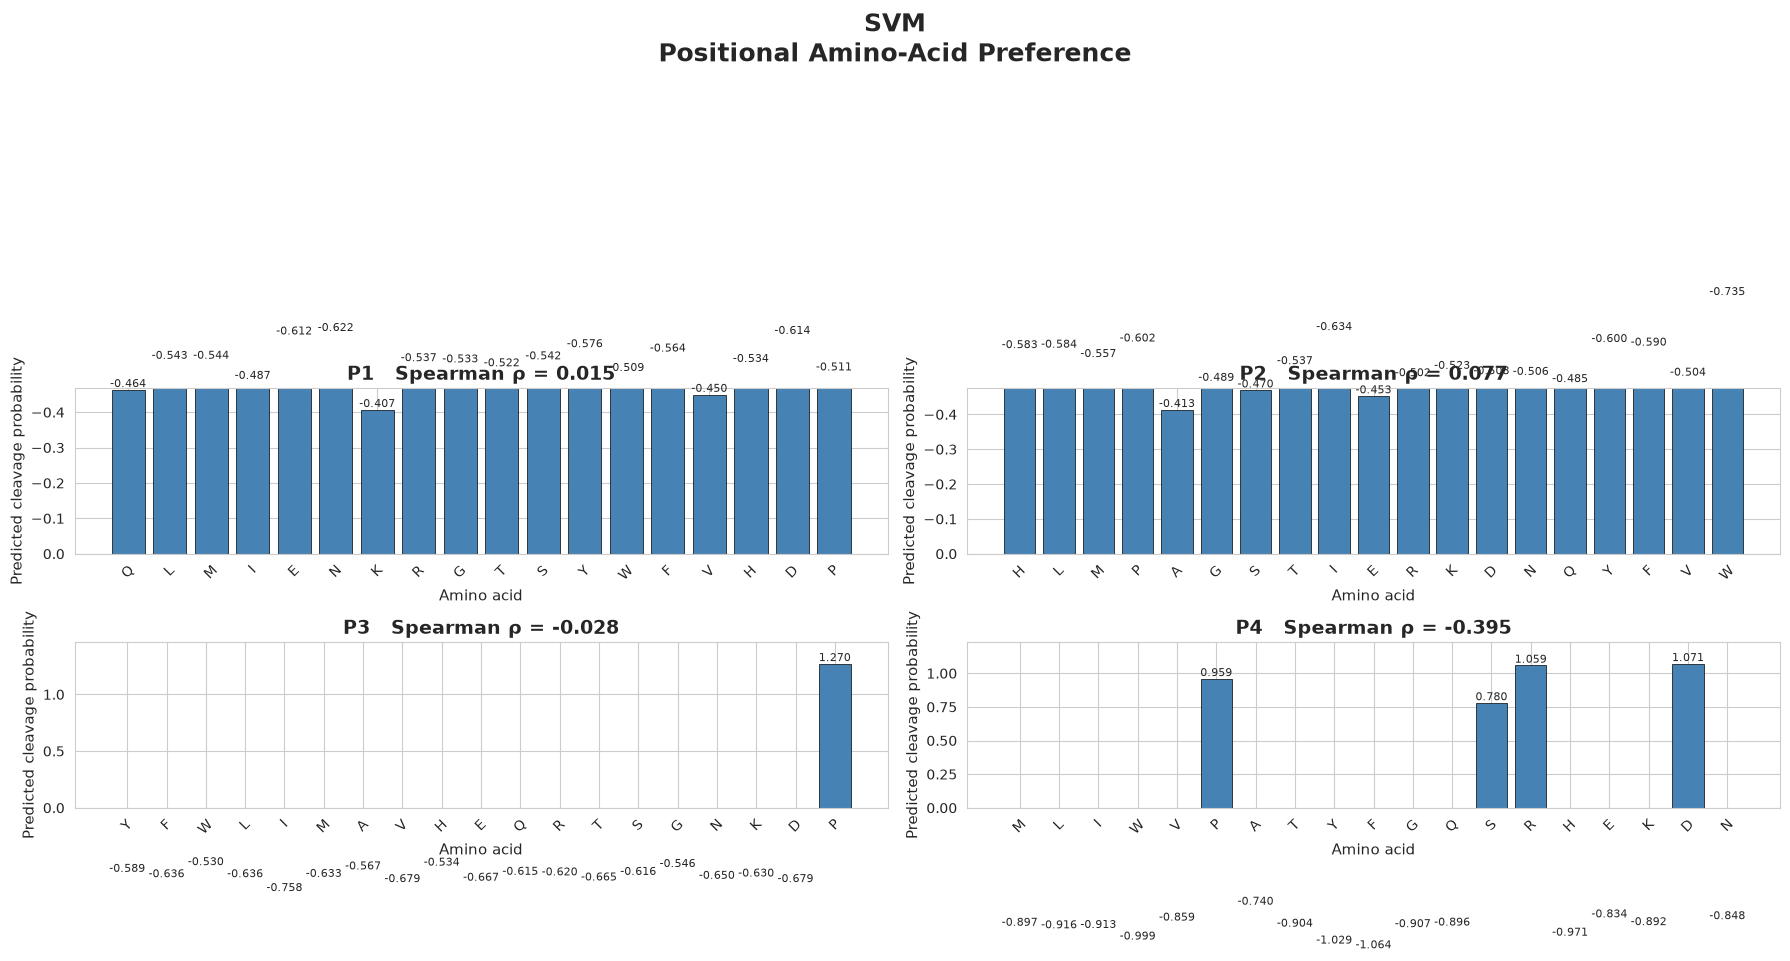

In [51]:
# ============================================================
# CELL 8 — SVM
# ============================================================

model_name = "SVM"


print("=" * 70)
print(model_name)
print("=" * 70)


# ------------------------------------------------------------
# Spearman
# ------------------------------------------------------------

model_spearman = spearman_df[
    spearman_df["Model"] == model_name
].copy()


display(
    model_spearman.round(4)
)


# ------------------------------------------------------------
# Preference table
# ------------------------------------------------------------

print("\nPositional preference:")

display(
    preference[
        model_name
    ].pivot(
        index="AA",
        columns="Position",
        values="Probability"
    ).round(4)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plot_model_preference(
    model_name,
    preference,
    experimental_orders
)


Decision Tree


,Model,Position,Spearman_rho,p_value,N_AA_compared
8,Decision Tree,P1,0.2933,0.2376,18
9,Decision Tree,P2,-0.0684,0.7809,19
10,Decision Tree,P3,-0.1752,0.4730,19
11,Decision Tree,P4,-0.2447,0.3127,19



Positional preference:


Position,P1,P2,P3,P4
AA,,,,
A,0.3289,0.4235,0.3888,0.3820
C,0.3283,0.4591,0.3407,0.3116
D,0.1739,0.3095,0.2760,0.6900
E,0.3151,0.4013,0.3287,0.3481
F,0.3286,0.2930,0.3407,0.0585
G,0.3291,0.4073,0.3761,0.2126
H,0.3283,0.2930,0.3407,0.3116
I,0.3976,0.2765,0.2653,0.3116
K,0.4492,0.3657,0.3732,0.3390


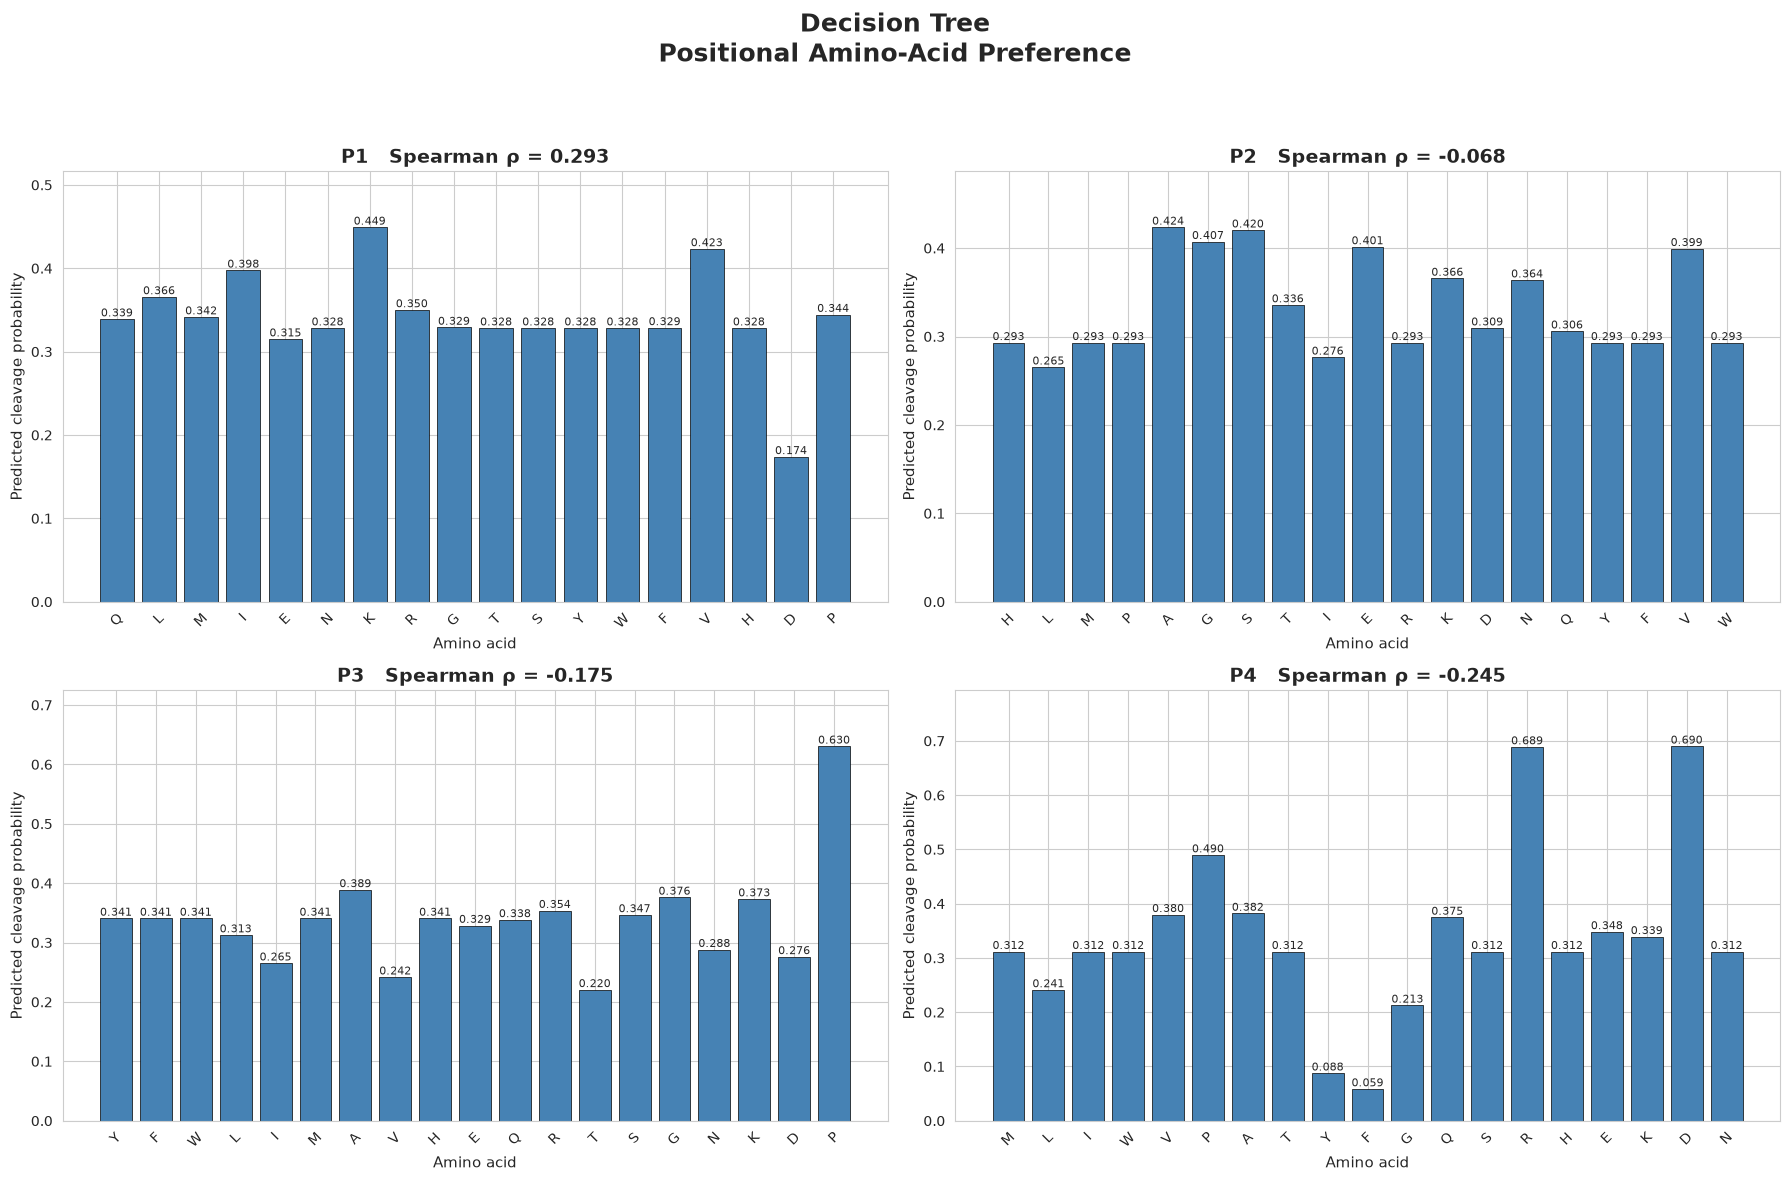

In [52]:
# ============================================================
# CELL 9 — DECISION TREE
# ============================================================

model_name = "Decision Tree"


print("=" * 70)
print(model_name)
print("=" * 70)


# ------------------------------------------------------------
# Spearman
# ------------------------------------------------------------

model_spearman = spearman_df[
    spearman_df["Model"] == model_name
].copy()


display(
    model_spearman.round(4)
)


# ------------------------------------------------------------
# Preference table
# ------------------------------------------------------------

print("\nPositional preference:")

display(
    preference[
        model_name
    ].pivot(
        index="AA",
        columns="Position",
        values="Probability"
    ).round(4)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plot_model_preference(
    model_name,
    preference,
    experimental_orders
)


Random Forest


,Model,Position,Spearman_rho,p_value,N_AA_compared
12,Random Forest,P1,0.2632,0.2914,18
13,Random Forest,P2,0.1316,0.5913,19
14,Random Forest,P3,-0.0860,0.7264,19
15,Random Forest,P4,-0.3719,0.1169,19



Positional preference:


Position,P1,P2,P3,P4
AA,,,,
A,0.3875,0.4546,0.4092,0.4266
C,0.3684,0.4283,0.3367,0.3728
D,0.2614,0.3902,0.3121,0.7049
E,0.3044,0.4534,0.3542,0.3829
F,0.3603,0.3226,0.3736,0.1193
G,0.3730,0.4094,0.4357,0.3234
H,0.3562,0.3596,0.4028,0.3192
I,0.4308,0.3140,0.2576,0.3369
K,0.4372,0.3980,0.3913,0.3627


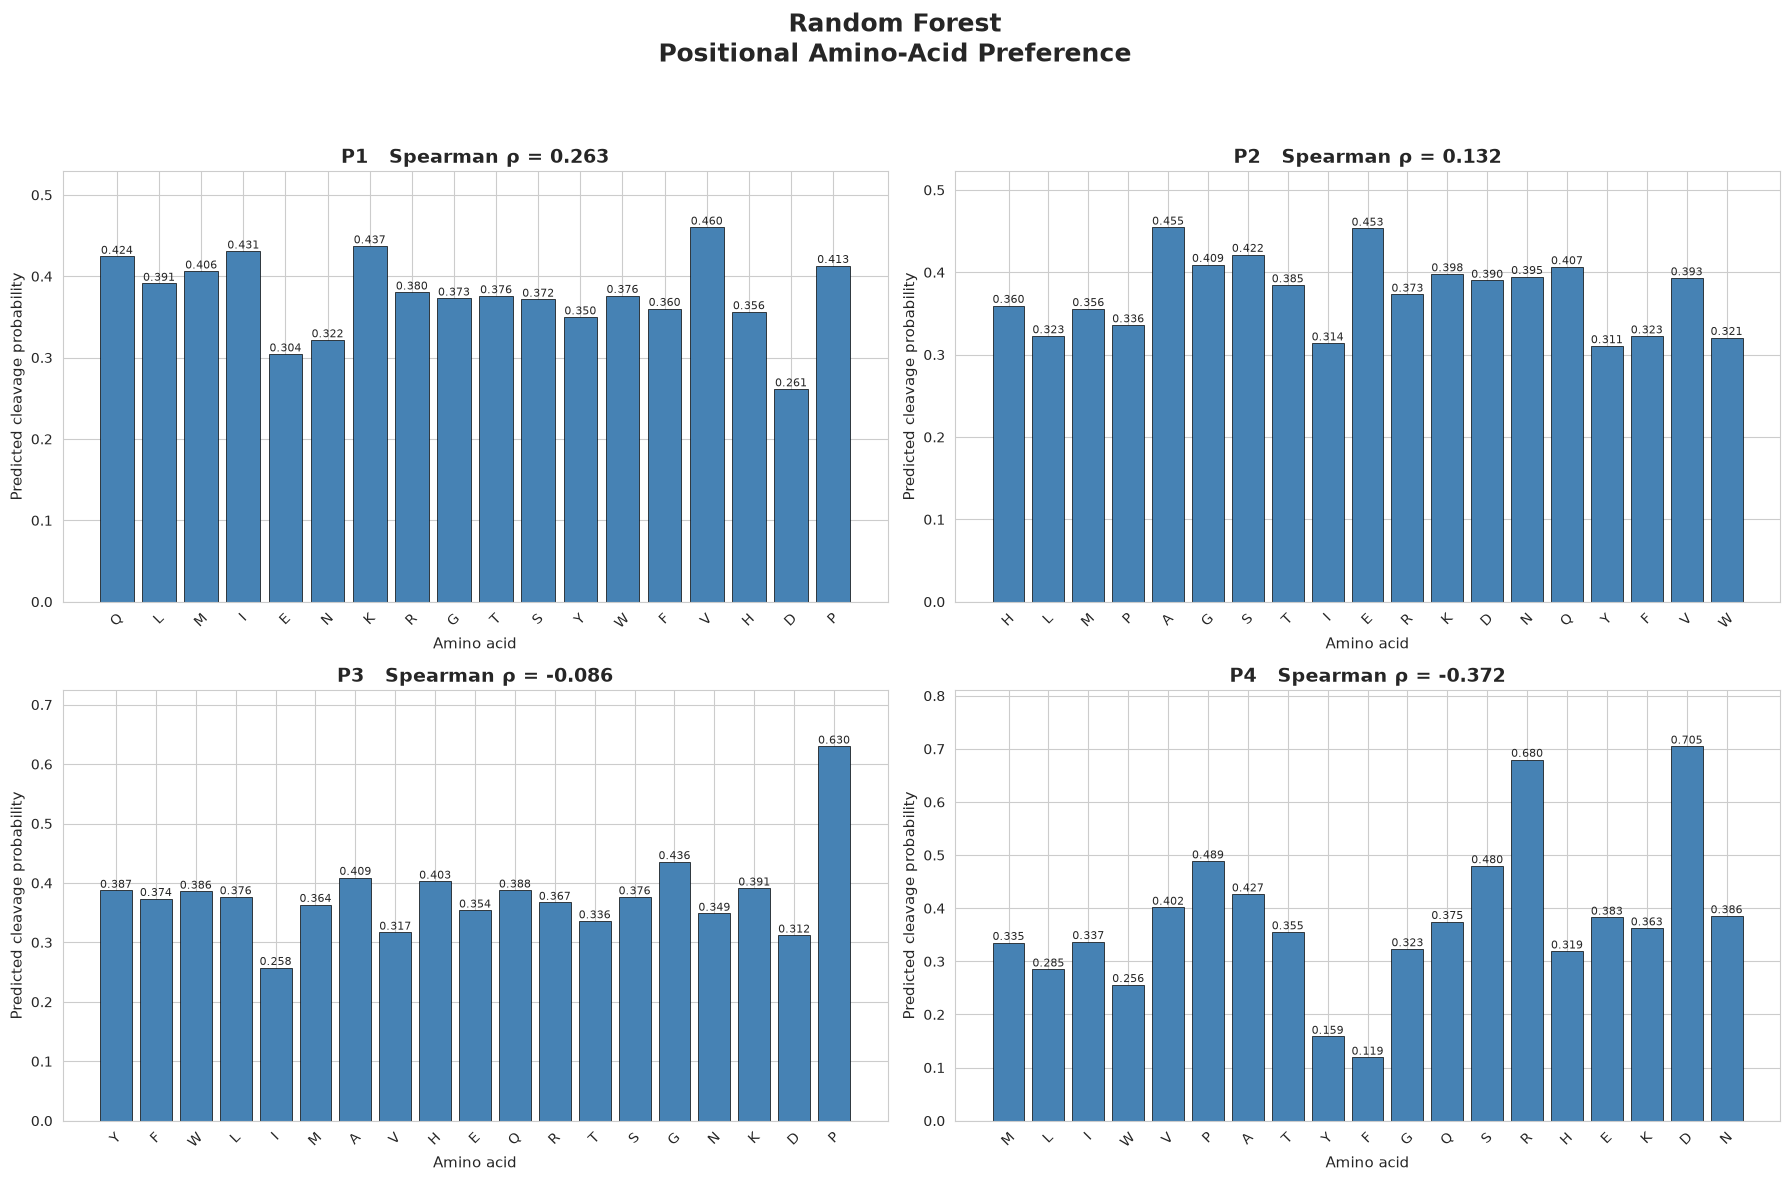

In [53]:
# ============================================================
# CELL 10 — RANDOM FOREST
# ============================================================

model_name = "Random Forest"


print("=" * 70)
print(model_name)
print("=" * 70)


# ------------------------------------------------------------
# Spearman
# ------------------------------------------------------------

model_spearman = spearman_df[
    spearman_df["Model"] == model_name
].copy()


display(
    model_spearman.round(4)
)


# ------------------------------------------------------------
# Preference table
# ------------------------------------------------------------

print("\nPositional preference:")

display(
    preference[
        model_name
    ].pivot(
        index="AA",
        columns="Position",
        values="Probability"
    ).round(4)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plot_model_preference(
    model_name,
    preference,
    experimental_orders
)


KNN


,Model,Position,Spearman_rho,p_value,N_AA_compared
16,KNN,P1,0.3127,0.2065,18
17,KNN,P2,0.2175,0.3710,19
18,KNN,P3,0.0772,0.7534,19
19,KNN,P4,-0.4105,0.0808,19



Positional preference:


Position,P1,P2,P3,P4
AA,,,,
A,0.4069,0.4679,0.4279,0.4502
C,0.3861,0.4861,0.3239,0.3768
D,0.2927,0.4317,0.2844,0.6191
E,0.3067,0.4631,0.3772,0.4187
F,0.3769,0.3450,0.4083,0.2831
G,0.3473,0.4458,0.4783,0.3808
H,0.3508,0.4098,0.3950,0.2957
I,0.5009,0.3253,0.2665,0.3318
K,0.4525,0.3800,0.3996,0.4018


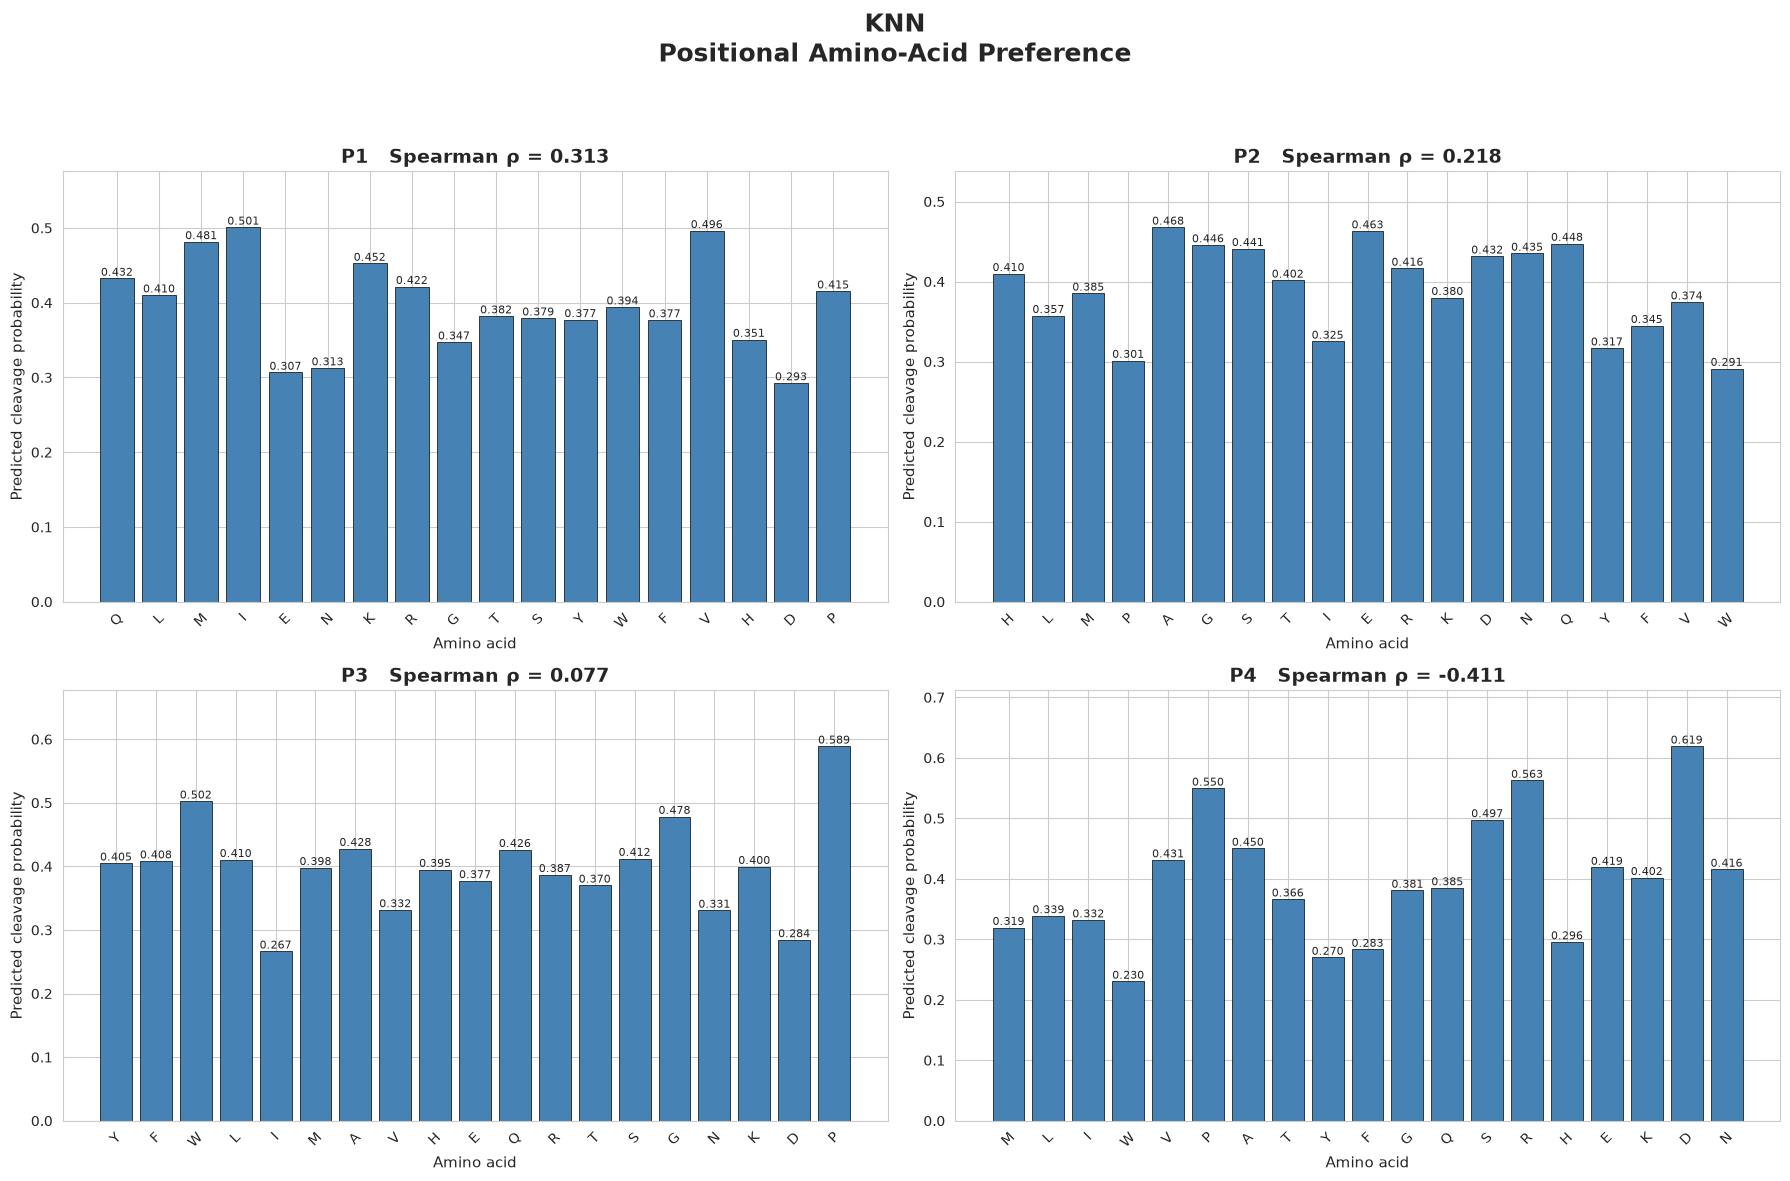

In [54]:
# ============================================================
# CELL 11 — KNN
# ============================================================

model_name = "KNN"


print("=" * 70)
print(model_name)
print("=" * 70)


# ------------------------------------------------------------
# Spearman
# ------------------------------------------------------------

model_spearman = spearman_df[
    spearman_df["Model"] == model_name
].copy()


display(
    model_spearman.round(4)
)


# ------------------------------------------------------------
# Preference table
# ------------------------------------------------------------

print("\nPositional preference:")

display(
    preference[
        model_name
    ].pivot(
        index="AA",
        columns="Position",
        values="Probability"
    ).round(4)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plot_model_preference(
    model_name,
    preference,
    experimental_orders
)


XGBoost


,Model,Position,Spearman_rho,p_value,N_AA_compared
20,XGBoost,P1,0.2322,0.3538,18
21,XGBoost,P2,0.0965,0.6943,19
22,XGBoost,P3,-0.0333,0.8922,19
23,XGBoost,P4,-0.3421,0.1517,19



Positional preference:


Position,P1,P2,P3,P4
AA,,,,
A,0.3312,0.4312,0.3701,0.3746
C,0.2570,0.4041,0.2234,0.2781
D,0.1779,0.3483,0.2250,0.7223
E,0.2143,0.4403,0.2727,0.3120
F,0.2898,0.2333,0.2936,0.0468
G,0.3222,0.3867,0.4178,0.2227
H,0.3085,0.2714,0.3989,0.1546
I,0.3923,0.2064,0.1526,0.2086
K,0.3983,0.3518,0.3102,0.2997


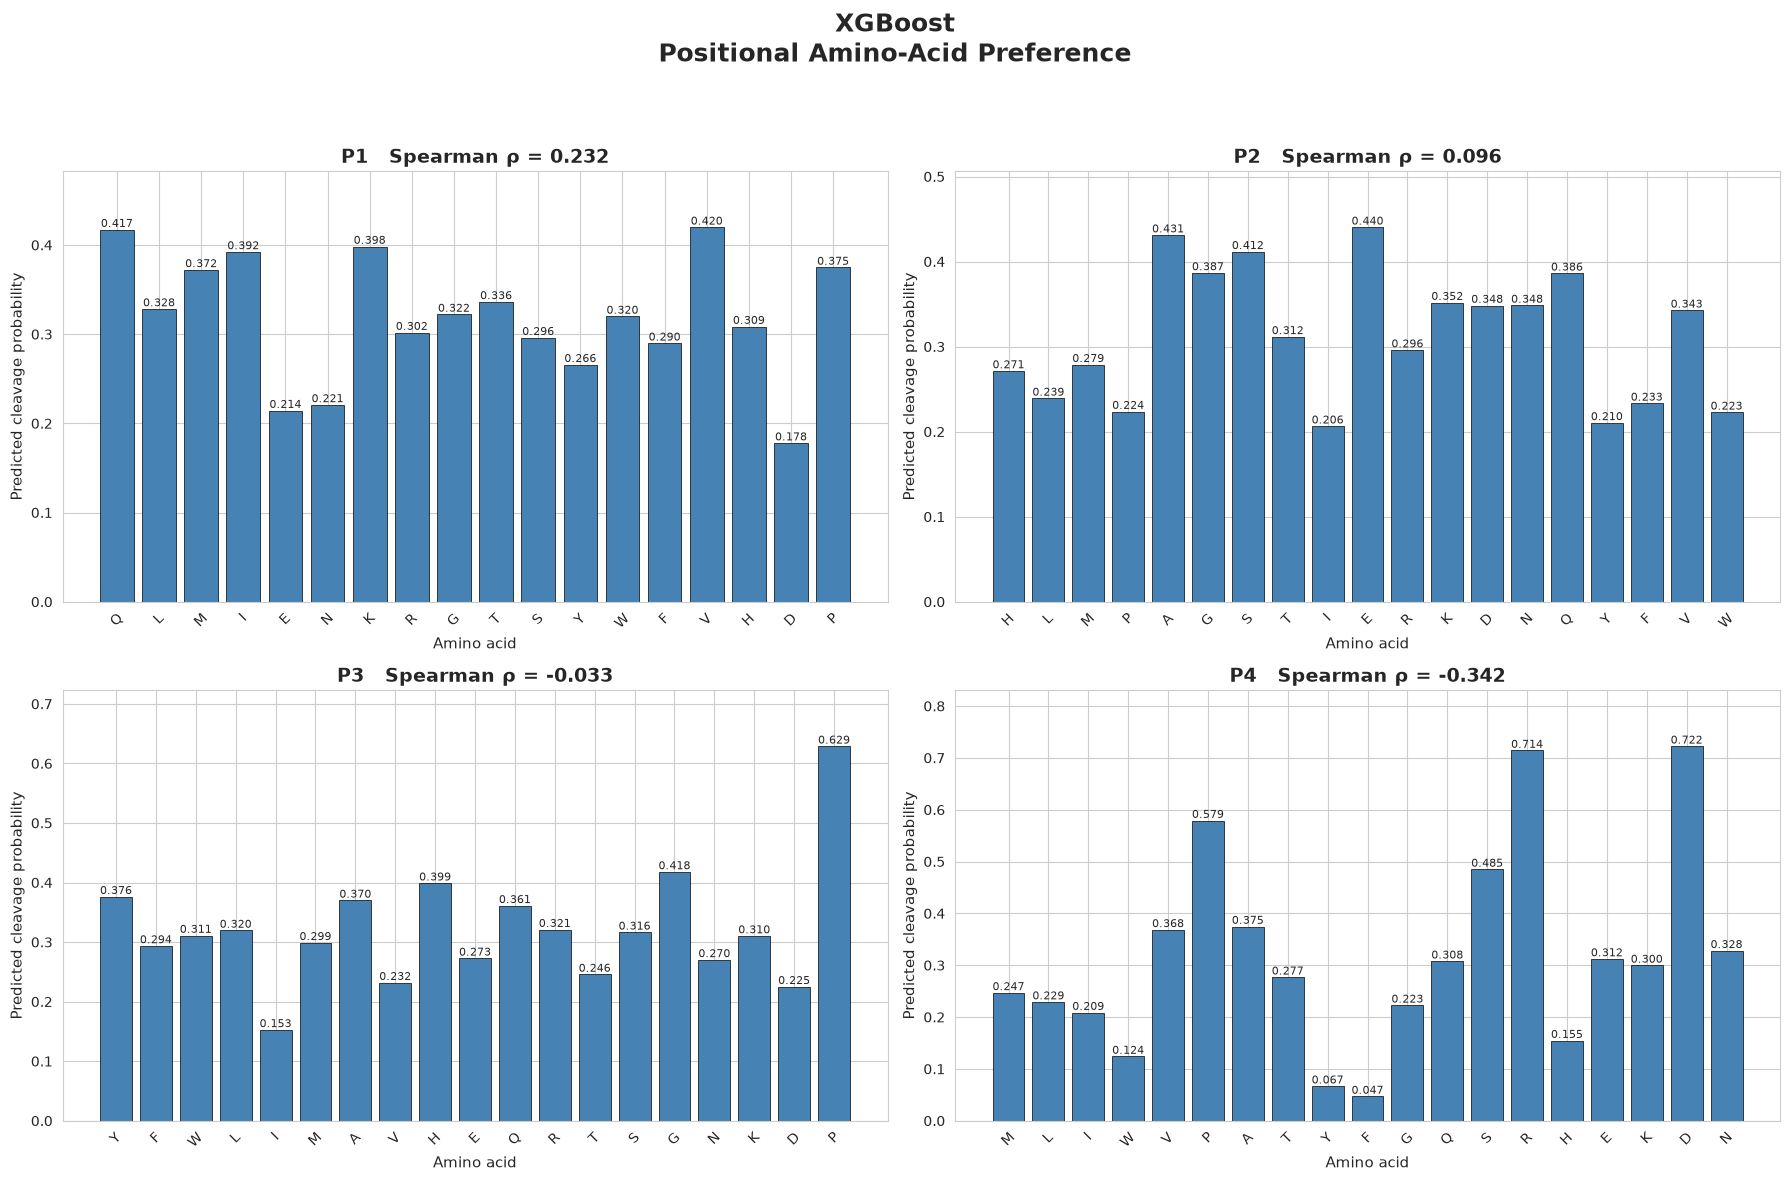

In [55]:
# ============================================================
# CELL 12 — XGBOOST
# ============================================================

model_name = "XGBoost"


print("=" * 70)
print(model_name)
print("=" * 70)


# ------------------------------------------------------------
# Spearman
# ------------------------------------------------------------

model_spearman = spearman_df[
    spearman_df["Model"] == model_name
].copy()


display(
    model_spearman.round(4)
)


# ------------------------------------------------------------
# Preference table
# ------------------------------------------------------------

print("\nPositional preference:")

display(
    preference[
        model_name
    ].pivot(
        index="AA",
        columns="Position",
        values="Probability"
    ).round(4)
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plot_model_preference(
    model_name,
    preference,
    experimental_orders
)
